<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/MlLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Task 1 Correlation Matrix ---


,bmi,target
bmi,1.00000,0.58645
target,0.58645,1.00000


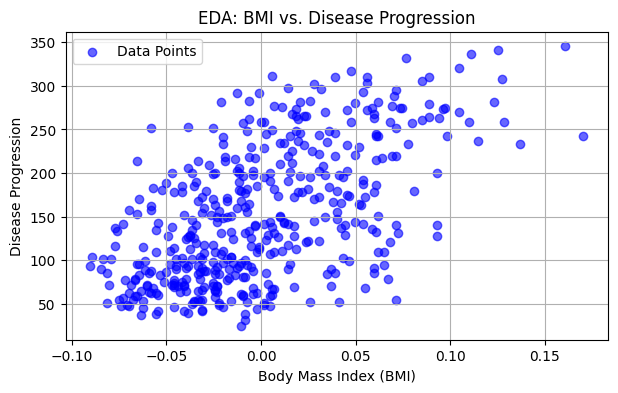

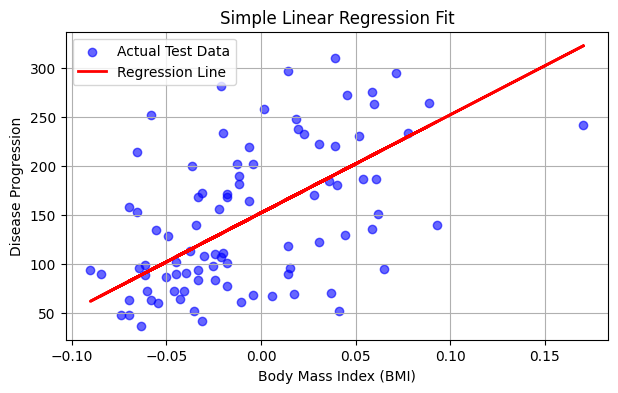


--- Task 1 Evaluation ---
Mean Squared Error (MSE) : 4061.8259
R² Score                  : 0.2334


In [ ]:
# TASK 1: SIMPLE LINEAR REGRESSION (BMI ONLY)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset directly from sklearn
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

X_simple = df[['bmi']]
y = df['target']

# 2. Exploratory Data Analysis (EDA)
print("--- Task 1 Correlation Matrix ---")
display(df[['bmi', 'target']].corr())

plt.figure(figsize=(7, 4))
plt.scatter(X_simple, y, alpha=0.6, color='blue', label='Data Points')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Disease Progression')
plt.title('EDA: BMI vs. Disease Progression')
plt.grid(True)
plt.legend()
plt.show()

# 3. Model Training & Prediction
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)
y_pred_s = simple_model.predict(X_test_s)

# Plot Regression Line
plt.figure(figsize=(7, 4))
plt.scatter(X_test_s, y_test_s, alpha=0.6, color='blue', label='Actual Test Data')
plt.plot(X_test_s, y_pred_s, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Disease Progression')
plt.title('Simple Linear Regression Fit')
plt.grid(True)
plt.legend()
plt.show()

# 4. Evaluation Metrics
mse_s = mean_squared_error(y_test_s, y_pred_s)
r2_s = r2_score(y_test_s, y_pred_s)

print("\n--- Task 1 Evaluation ---")
print(f"Mean Squared Error (MSE) : {mse_s:.4f}")
print(f"R² Score                  : {r2_s:.4f}")

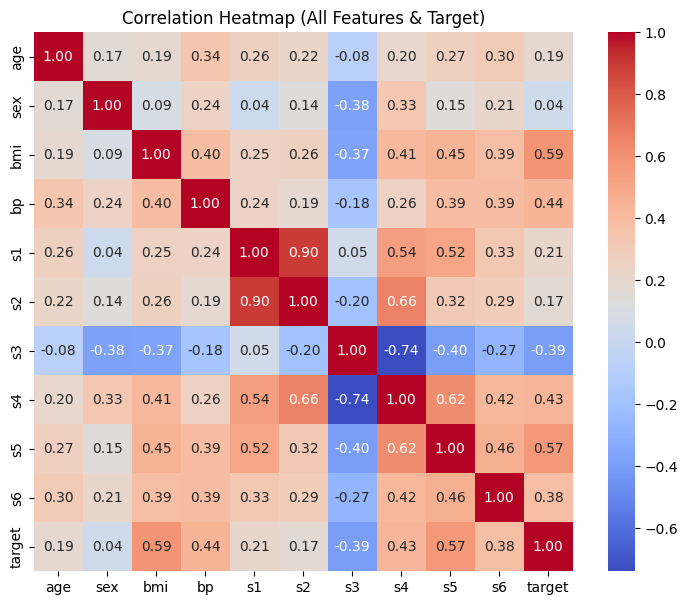

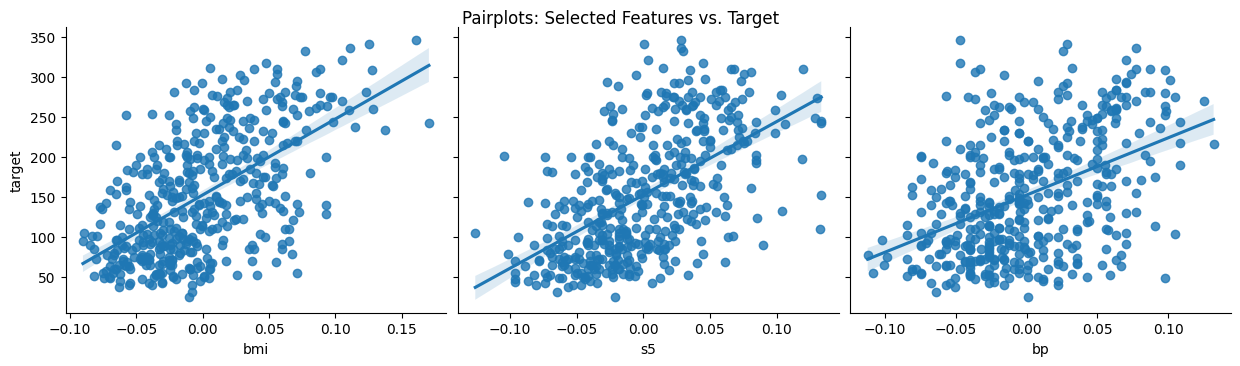

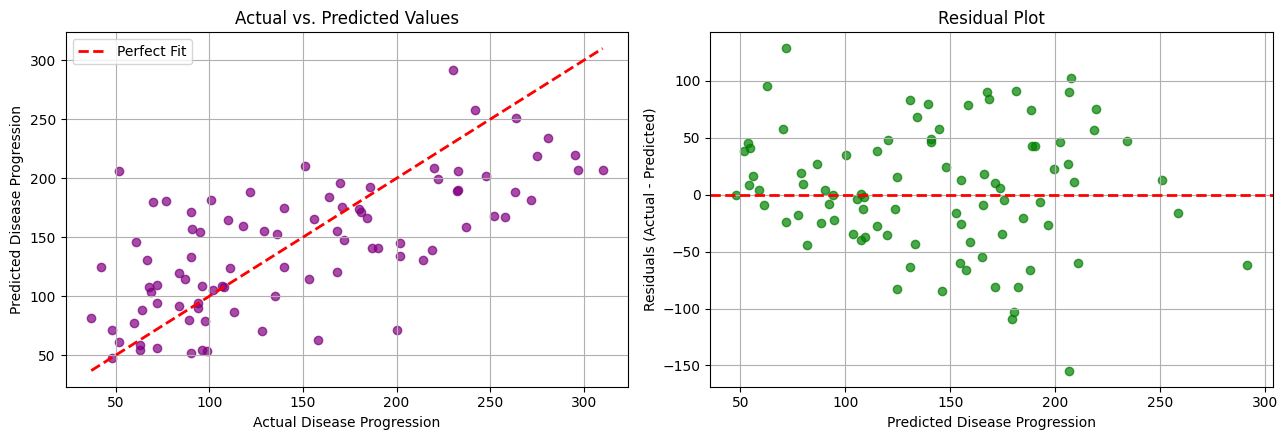

--- Task 2 Evaluation ---
Mean Squared Error (MSE) : 2900.1936
Root Mean Squared Error (RMSE): 53.8534
R² Score                  : 0.4526

--- Feature Contributions (Model Coefficients) ---


,Feature,Coefficient
4,s1,-931.488846
8,s5,736.198859
2,bmi,542.428759
5,s2,518.062277
3,bp,347.703844
7,s4,275.317902
1,sex,-241.964362
6,s3,163.419983
9,s6,48.670657
0,age,37.904021


In [ ]:
# ==========================================
# TASK 2: MULTIVARIATE LINEAR REGRESSION (ALL FEATURES)
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset directly from sklearn
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

X_multi = df.drop(columns=['target'])
y = df['target']

# 2. EDA: Correlation Heatmap & Pair Plots
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Heatmap (All Features & Target)')
plt.show()

# Pair plots for key features vs. target
sns.pairplot(df, x_vars=['bmi', 's5', 'bp'], y_vars=['target'], height=3.5, aspect=1.2, kind='reg')
plt.suptitle('Pairplots: Selected Features vs. Target', y=1.02)
plt.show()

# 3. Model Training & Prediction
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)
y_pred_m = multi_model.predict(X_test_m)

# 4. Compare Actual vs. Predicted & Residual Plot
plt.figure(figsize=(13, 4.5))

# Scatter Plot: Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test_m, y_pred_m, alpha=0.7, color='purple')
plt.plot([y_test_m.min(), y_test_m.max()], [y_test_m.min(), y_test_m.max()], 'r--', lw=2, label='Perfect Fit')
plt.xlabel('Actual Disease Progression')
plt.ylabel('Predicted Disease Progression')
plt.title('Actual vs. Predicted Values')
plt.legend()
plt.grid(True)

# Residual Plot
residuals = y_test_m - y_pred_m
plt.subplot(1, 2, 2)
plt.scatter(y_pred_m, residuals, alpha=0.7, color='green')
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.xlabel('Predicted Disease Progression')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot')
plt.grid(True)

plt.tight_layout()
plt.show()

# 5. Evaluation Metrics
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test_m, y_pred_m)

print("--- Task 2 Evaluation ---")
print(f"Mean Squared Error (MSE) : {mse_m:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_m:.4f}")
print(f"R² Score                  : {r2_m:.4f}")

# Rank feature contributions by regression coefficients
coefficients = pd.DataFrame({
    'Feature': X_multi.columns,
    'Coefficient': multi_model.coef_
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("\n--- Feature Contributions (Model Coefficients) ---")
display(coefficients)

In [ ]:
# ==========================================
# TASK 3: EXPERIMENTATION & COMPARISON
# ==========================================
import pandas as pd
import numpy as np

rmse_s = np.sqrt(mse_s)

# Create comparison table using metrics calculated in previous cells
comparison_df = pd.DataFrame({
    'Metric': ['MSE', 'RMSE', 'R² Score'],
    'Simple Linear Regression (BMI Only)': [f"{mse_s:.4f}", f"{rmse_s:.4f}", f"{r2_s:.4f}"],
    'Multivariate Linear Regression (All Features)': [f"{mse_m:.4f}", f"{rmse_m:.4f}", f"{r2_m:.4f}"]
})

print("--- Task 3: Performance Comparison Table ---")
display(comparison_df)

--- Task 3: Performance Comparison Table ---


,Metric,Simple Linear Regression (BMI Only),Multivariate Linear Regression (All Features)
0,MSE,4061.8259,2900.1936
1,RMSE,63.7325,53.8534
2,R² Score,0.2334,0.4526
